<a href="https://colab.research.google.com/github/Koushik2612/fds-lab/blob/main/fds_case_study_(38).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2) (1).zip


In [4]:
import zipfile
import os

# Extract the uploaded zip file
zip_path = 'archive (2) (1).zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('extracted_data')

# Find and load the CSV file inside the extracted directory
extracted_files = os.listdir('extracted_data')
print("Extracted files:", extracted_files)

csv_files = [f for f in extracted_files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join('extracted_data', csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"Successfully loaded {csv_files[0]} into DataFrame 'df'")
else:
    print("No CSV file found in the archive. Please check the extracted files.")

Extracted files: ['german_credit_data.csv']
Successfully loaded german_credit_data.csv into DataFrame 'df'


In [5]:
print("Shape of Dataset:", df.shape)

display(df.head())

df.info()

display(df.describe())

Shape of Dataset: (1000, 21)


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,...,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.577000,20.903000,2.54500,2.828000,3271.24800,2.105000,3.384000,2.973000,2.68200,1.145000,...,2.358000,35.54200,2.675000,1.928000,1.407000,2.904000,1.845000,1.404000,1.963000,0.700000
std,1.257638,12.058814,1.08312,2.744439,2822.75176,1.580023,1.208306,1.118715,0.70808,0.477706,...,1.050209,11.35267,0.705601,0.530186,0.577654,0.653614,0.362086,0.490943,0.188856,0.458487
min,1.000000,4.000000,0.00000,0.000000,250.00000,1.000000,1.000000,1.000000,1.00000,1.000000,...,1.000000,19.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.00000,1.000000,1365.50000,1.000000,3.000000,2.000000,2.00000,1.000000,...,1.000000,27.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,18.000000,2.00000,2.000000,2319.50000,1.000000,3.000000,3.000000,3.00000,1.000000,...,2.000000,33.00000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,1.000000
75%,4.000000,24.000000,4.00000,3.000000,3972.25000,3.000000,5.000000,4.000000,3.00000,1.000000,...,3.000000,42.00000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.00000,10.000000,18424.00000,5.000000,5.000000,4.000000,4.00000,3.000000,...,4.000000,75.00000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


In [6]:
missing = df.isnull().sum()
print(missing)

laufkont    0
laufzeit    0
moral       0
verw        0
hoehe       0
sparkont    0
beszeit     0
rate        0
famges      0
buerge      0
wohnzeit    0
verm        0
alter       0
weitkred    0
wohn        0
bishkred    0
beruf       0
pers        0
telef       0
gastarb     0
kredit      0
dtype: int64


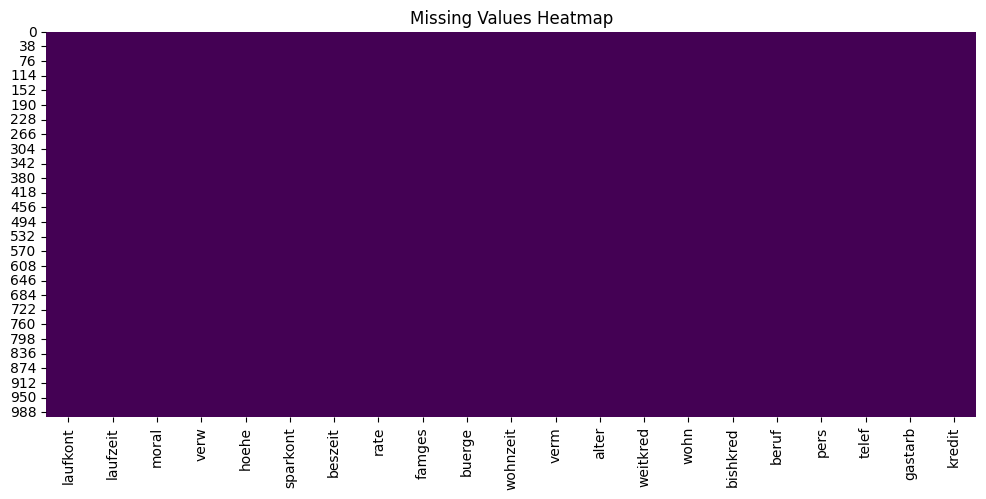

In [7]:
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

In [8]:
duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


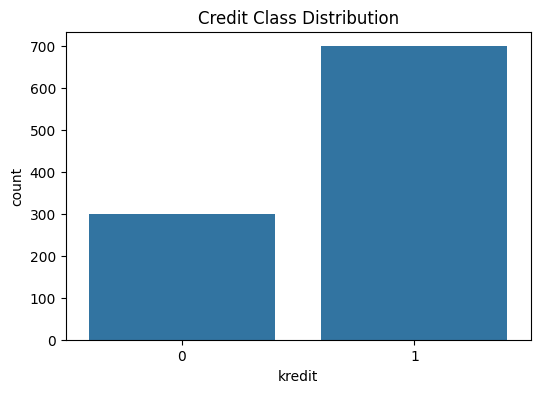

In [9]:
plt.figure(figsize=(6,4))
sns.countplot(x=df["kredit"])
plt.title("Credit Class Distribution")
plt.show()

In [10]:
df["kredit"].value_counts(normalize=True)*100

,proportion
kredit,
1,70.0
0,30.0


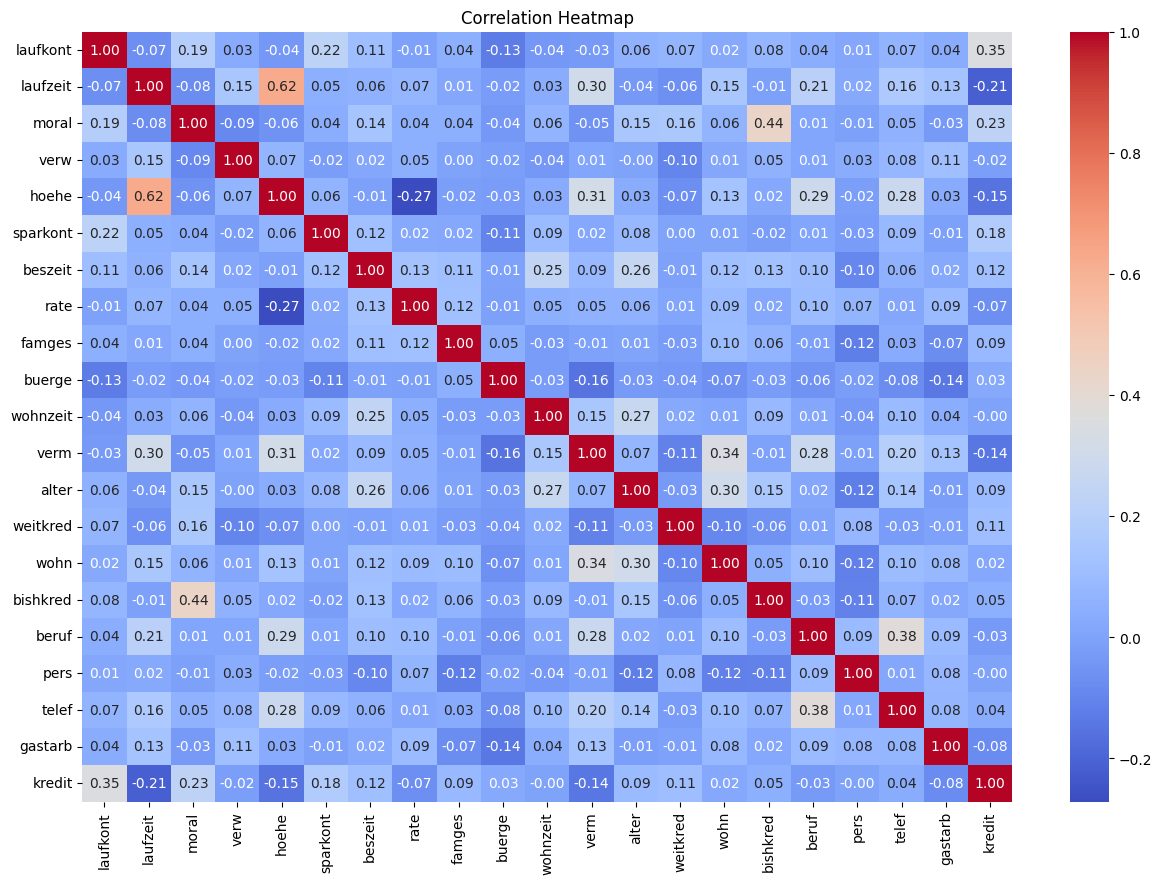

In [11]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

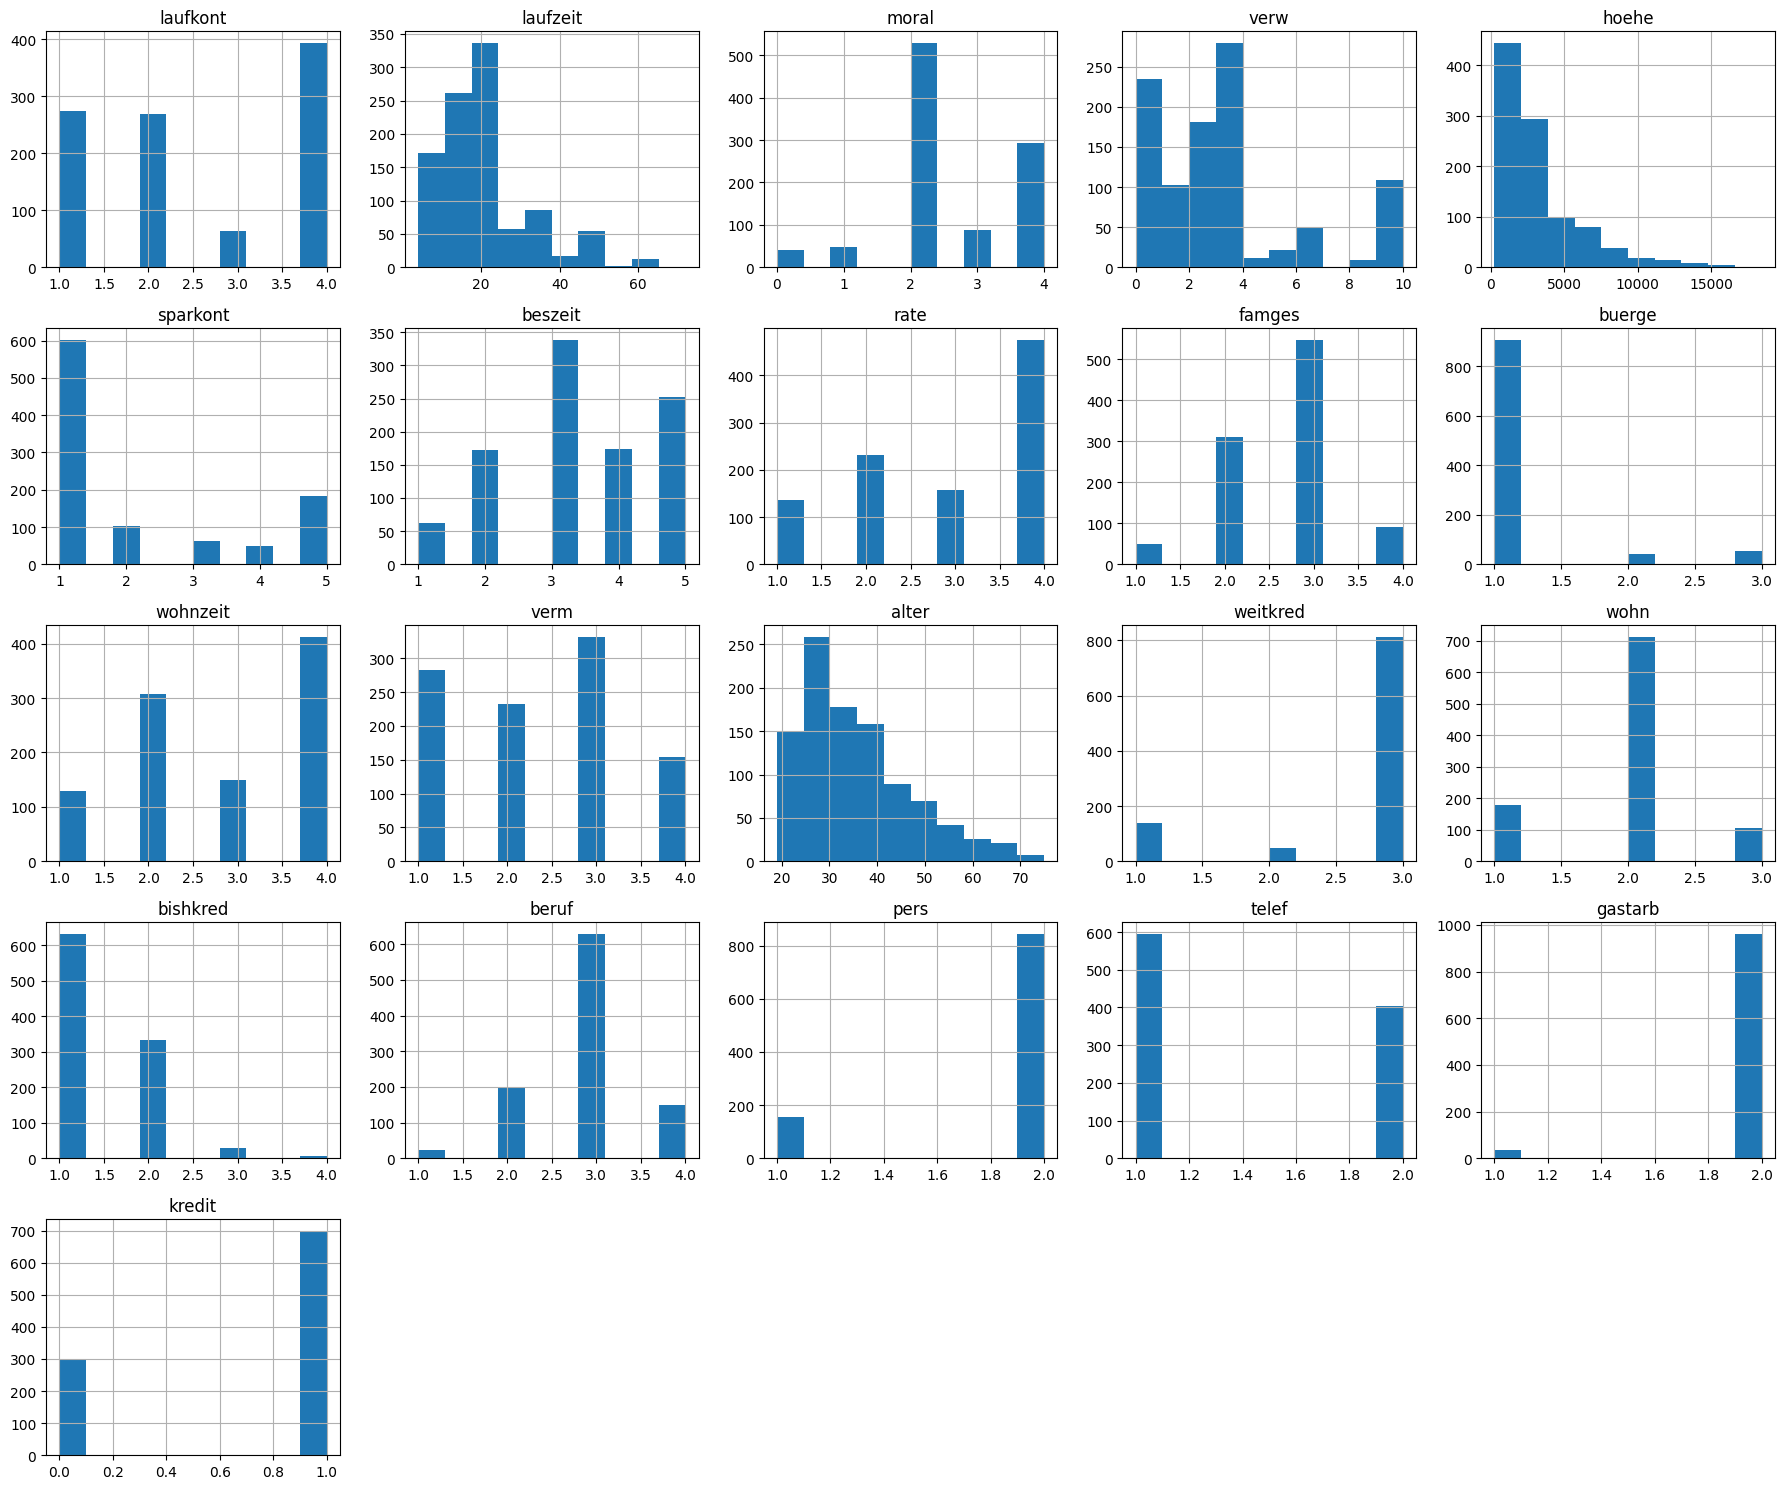

In [13]:
df.hist(figsize=(18,15))
plt.tight_layout()
plt.show()

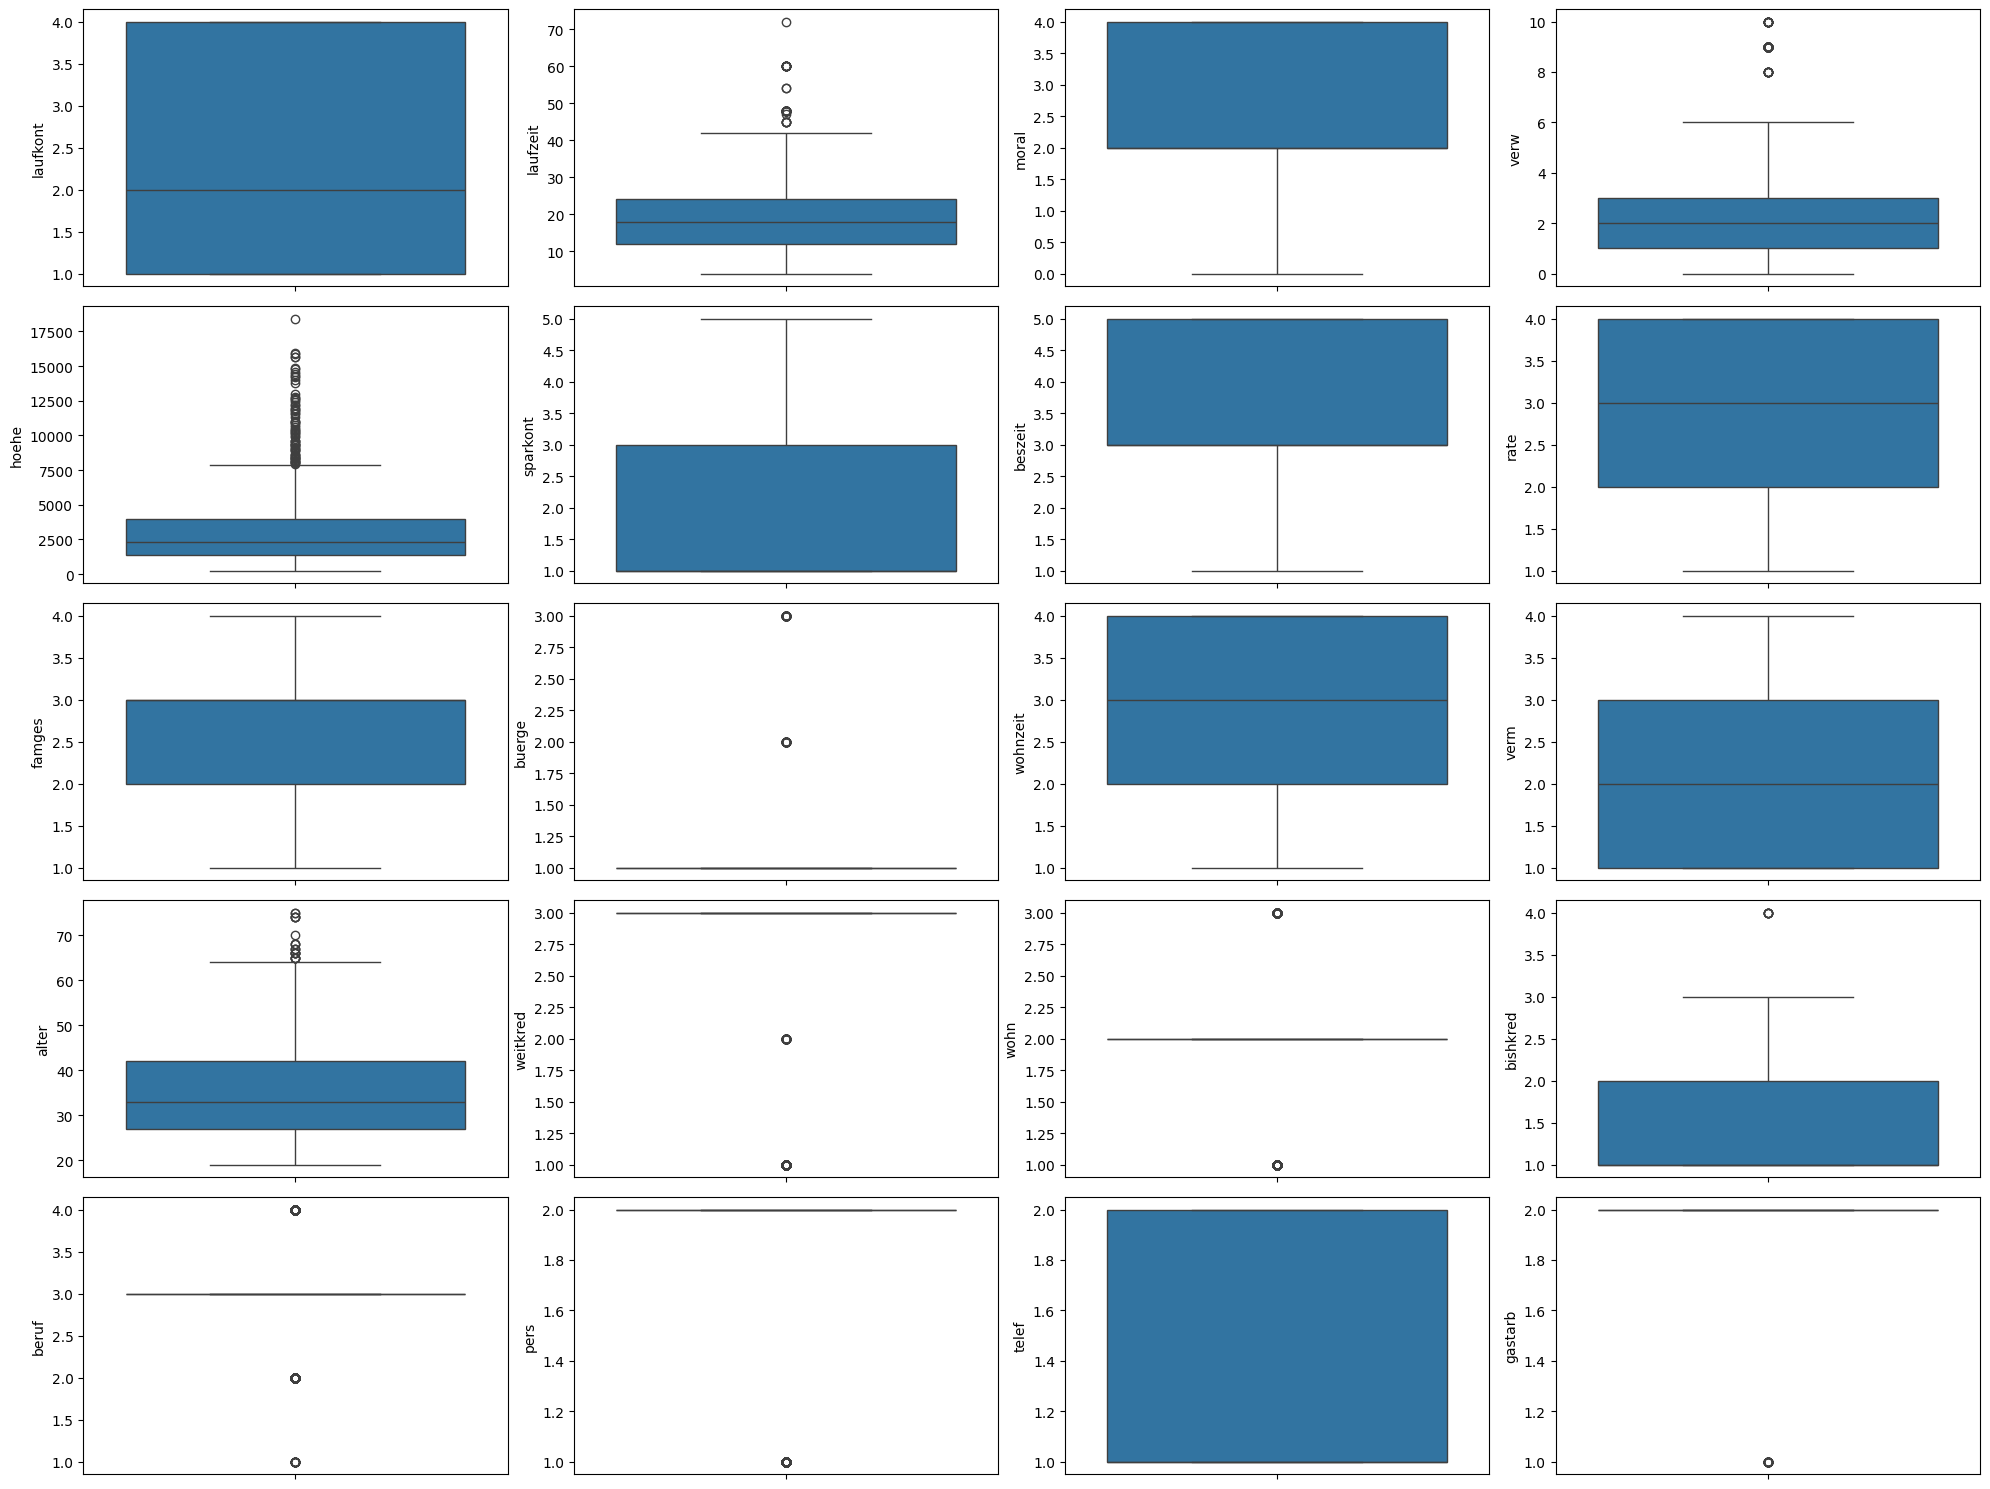

In [14]:
plt.figure(figsize=(20,15))

for i, col in enumerate(df.columns[:-1]):
    plt.subplot(5,4,i+1)
    sns.boxplot(y=df[col])

plt.tight_layout()
plt.show()

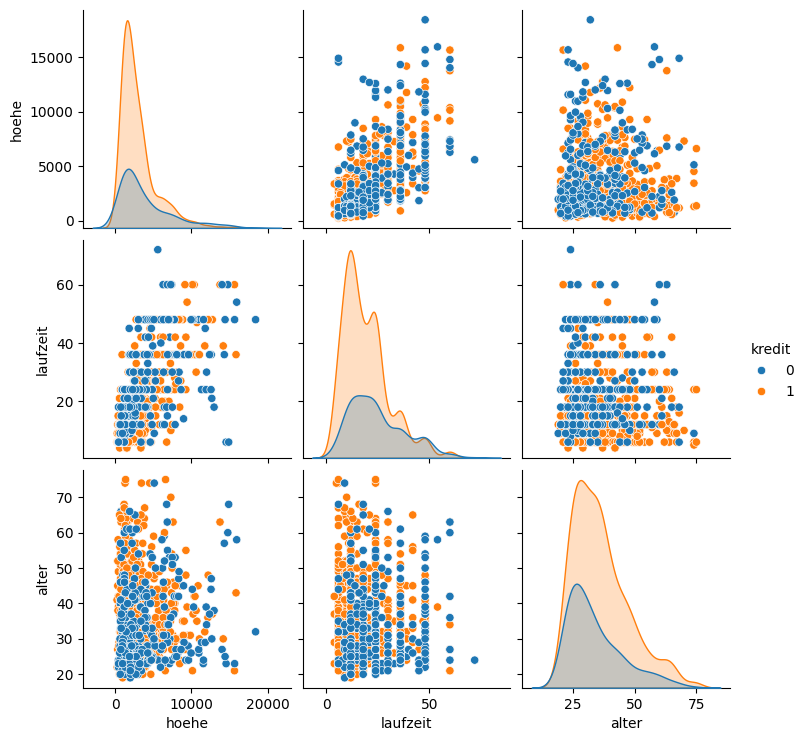

In [15]:
sns.pairplot(df[["hoehe","laufzeit","alter","kredit"]], hue="kredit")
plt.show()

In [16]:
df = df.drop_duplicates()

print(df.shape)

(1000, 21)


In [17]:
df.fillna(df.median(), inplace=True)

In [18]:
df_processed = df.copy()

for col in df_processed.columns[:-1]:

    Q1 = df_processed[col].quantile(0.25)
    Q3 = df_processed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df_processed[col] = df_processed[col].clip(lower, upper)

df_processed.head()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049.0,1,2,4,2,1,...,2,21.0,3,2,1.0,3,2,1,2,1
1,1,9,4,0,2799.0,1,3,2,3,1,...,1,36.0,3,2,2.0,3,2,1,2,1
2,2,12,2,6,841.0,2,4,2,2,1,...,1,23.0,3,2,1.0,3,2,1,2,1
3,1,12,4,0,2122.0,1,3,3,3,1,...,1,39.0,3,2,2.0,3,2,1,2,1
4,1,12,4,0,2171.0,1,3,4,3,1,...,2,38.0,3,2,2.0,3,2,1,2,1


In [19]:
scaler = StandardScaler()

feature_cols = df_processed.columns.drop("kredit")

df_processed[feature_cols] = scaler.fit_transform(df_processed[feature_cols])

df_processed.head()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,-1.254566,-0.217440,1.344014,-0.234588,-0.915842,-0.699707,-1.145978,0.918477,-0.963650,0.0,...,-0.341055,-1.304413,0.0,0.0,-0.714978,0.0,0.0,-0.823318,0.0,1
1,-1.254566,-1.065709,1.344014,-1.230716,-0.115317,-0.699707,-0.317959,-0.870183,0.449326,0.0,...,-1.293723,0.049696,0.0,0.0,1.054770,0.0,0.0,-0.823318,0.0,1
2,-0.459026,-0.782952,-0.503428,1.757667,-1.010991,-0.066488,0.510060,-0.870183,-0.963650,0.0,...,-1.293723,-1.123865,0.0,0.0,-0.714978,0.0,0.0,-0.823318,0.0,1
3,-1.254566,-0.782952,1.344014,-1.230716,-0.425006,-0.699707,-0.317959,0.024147,0.449326,0.0,...,-1.293723,0.320518,0.0,0.0,1.054770,0.0,0.0,-0.823318,0.0,1
4,-1.254566,-0.782952,1.344014,-1.230716,-0.402591,-0.699707,-0.317959,0.918477,0.449326,0.0,...,-0.341055,0.230244,0.0,0.0,1.054770,0.0,0.0,-0.823318,0.0,1


In [20]:
df_processed.describe()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
count,1000.000000,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1000.0,...,1.000000e+03,1.000000e+03,1000.0,1000.0,1.000000e+03,1000.0,1000.0,1.000000e+03,1000.0,1000.000000
mean,0.000000,1.278977e-16,-2.842171e-17,-5.684342e-17,1.421085e-17,-5.684342e-17,9.947598e-17,9.947598e-17,8.881784e-17,0.0,...,-9.947598e-17,-3.907985e-17,0.0,0.0,2.149392e-16,0.0,0.0,8.881784e-17,0.0,0.700000
std,1.000500,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,0.0,...,1.000500e+00,1.000500e+00,0.0,0.0,1.000500e+00,0.0,0.0,1.000500e+00,0.0,0.458487
min,-1.254566,-1.536969e+00,-2.350870e+00,-1.230716e+00,-1.281339e+00,-6.997070e-01,-1.973997e+00,-1.764514e+00,-2.376626e+00,0.0,...,-1.293723e+00,-1.484961e+00,0.0,0.0,-7.149782e-01,0.0,0.0,-8.233179e-01,0.0,0.000000
25%,-1.254566,-7.829523e-01,-5.034280e-01,-7.326519e-01,-7.710618e-01,-6.997070e-01,-3.179592e-01,-8.701833e-01,-9.636499e-01,0.0,...,-1.293723e+00,-7.627695e-01,0.0,0.0,-7.149782e-01,0.0,0.0,-8.233179e-01,0.0,0.000000
50%,-0.459026,-2.174396e-01,-5.034280e-01,-2.345881e-01,-3.346612e-01,-6.997070e-01,-3.179592e-01,2.414692e-02,4.493265e-01,0.0,...,-3.410551e-01,-2.211260e-01,0.0,0.0,-7.149782e-01,0.0,0.0,-8.233179e-01,0.0,1.000000
75%,1.132053,3.480730e-01,1.344014e+00,2.634758e-01,4.213777e-01,5.667310e-01,1.338078e+00,9.184772e-01,4.493265e-01,0.0,...,6.116128e-01,5.913393e-01,0.0,0.0,1.054770e+00,0.0,0.0,1.214598e+00,0.0,1.000000
max,1.132053,2.044611e+00,1.344014e+00,1.757667e+00,2.210037e+00,1.833169e+00,1.338078e+00,9.184772e-01,1.862303e+00,0.0,...,1.564281e+00,2.622503e+00,0.0,0.0,3.709392e+00,0.0,0.0,1.214598e+00,0.0,1.000000


In [21]:
df_processed.to_csv("german_credit_preprocessed.csv", index=False)

from google.colab import files
files.download("german_credit_preprocessed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
laufkont,0,0.0
laufzeit,0,0.0
moral,0,0.0
verw,0,0.0
hoehe,0,0.0
sparkont,0,0.0
beszeit,0,0.0
rate,0,0.0
famges,0,0.0
buerge,0,0.0


In [23]:
print(df["kredit"].value_counts())

print("\nClass Percentage:")
print(df["kredit"].value_counts(normalize=True) * 100)

kredit
1    700
0    300
Name: count, dtype: int64

Class Percentage:
kredit
1    70.0
0    30.0
Name: proportion, dtype: float64


In [24]:
print("Minimum Values:")
print(df.min(numeric_only=True))

print("\nMaximum Values:")
print(df.max(numeric_only=True))

Minimum Values:
laufkont      1
laufzeit      4
moral         0
verw          0
hoehe       250
sparkont      1
beszeit       1
rate          1
famges        1
buerge        1
wohnzeit      1
verm          1
alter        19
weitkred      1
wohn          1
bishkred      1
beruf         1
pers          1
telef         1
gastarb       1
kredit        0
dtype: int64

Maximum Values:
laufkont        4
laufzeit       72
moral           4
verw           10
hoehe       18424
sparkont        5
beszeit         5
rate            4
famges          4
buerge          3
wohnzeit        4
verm            4
alter          75
weitkred        3
wohn            3
bishkred        4
beruf           4
pers            2
telef           2
gastarb         2
kredit          1
dtype: int64


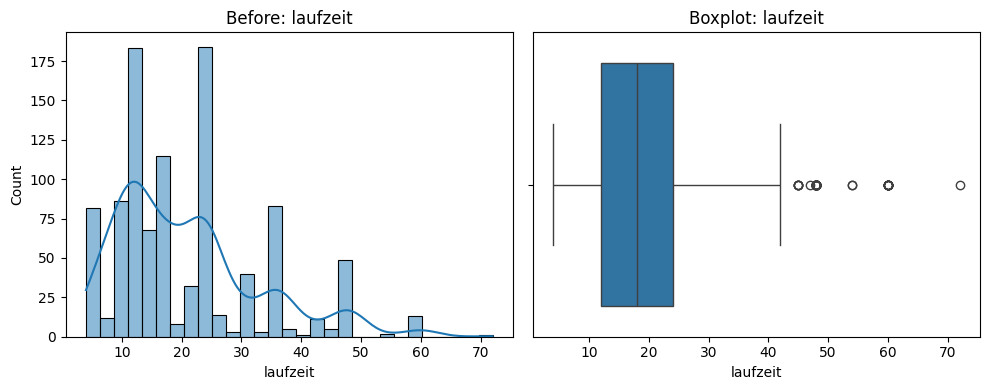

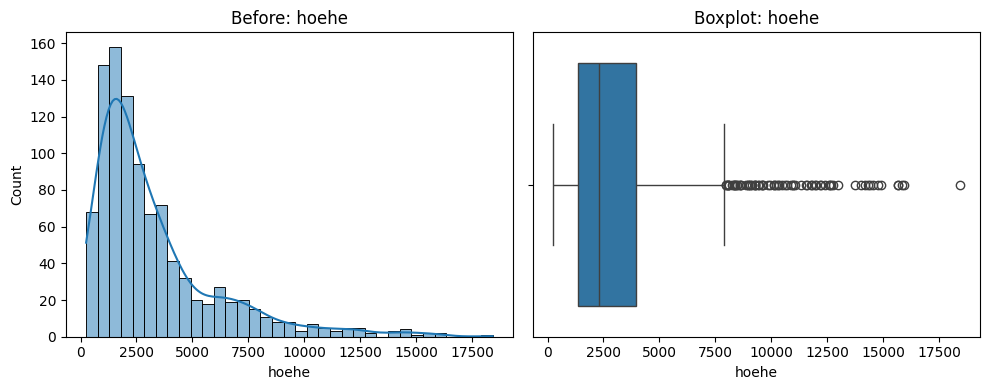

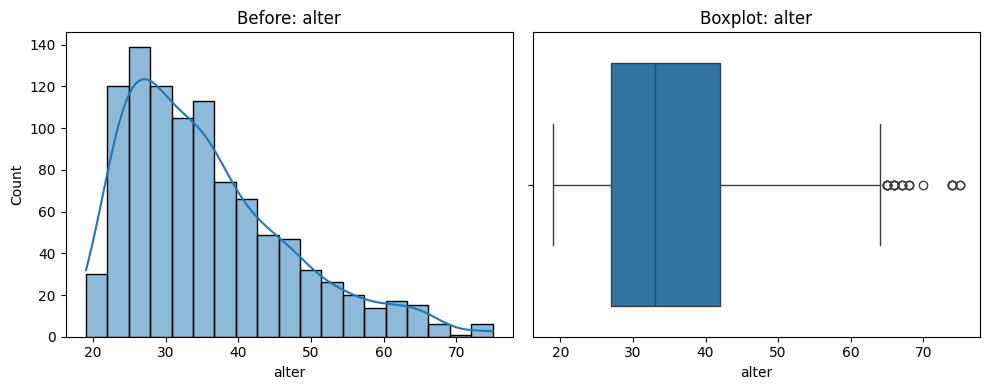

In [25]:
for col in ["laufzeit", "hoehe", "alter"]:
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True)
    plt.title(f"Before: {col}")

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")

    plt.tight_layout()
    plt.show()

In [26]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts(dropna=False))

    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()